# Glioma SS BENCH Pipeline

--------

In [1]:
import numpy as np
import matplotlib as plt
import numba
import scipy
import subprocess
import random
import os

from bench import diffusion_models
from bench.diffusion_models import sample_signal, standard_model
from fsl.data.image import Image
from fsl.wrappers.fslmaths import fslmaths
from fsl.wrappers import bet, flirt, fnirt, applywarp
from fsl.utils.image.roi import roi

In [2]:
bvecs = "/Users/ecd25/Desktop/BENCH/BENCH_Tutorial/one_vs_many/preop/b0b1200.bvec"
bvals = "/Users/ecd25/Desktop/BENCH/BENCH_Tutorial/one_vs_many/preop/b0b1200.bval"
#mask = "/Users/ecd25/Desktop/BENCH/wm_mask_2mm.nii.gz"
standard_model_dt = "/Users/ecd25/Desktop/Fall_26/trained_models/ss_preop_standard_model_dt"

In [3]:

os.environ["FSLDIR"] = "/Users/ecd25/fsl"
os.environ["FSLOUTPUTTYPE"] = "NIFTI_GZ"
os.environ["PATH"] = "/Users/ecd25/fsl/bin:" + os.environ["PATH"]

In [4]:
print("FSLDIR:", os.environ["FSLDIR"])
print("FSLOUTPUTTYPE:", os.environ["FSLOUTPUTTYPE"])

import shutil
print("BET:", shutil.which("bet"))

FSLDIR: /Users/ecd25/fsl
FSLOUTPUTTYPE: NIFTI_GZ
BET: /Users/ecd25/fsl/bin/bet


In [5]:
!bench diff-train --model standard_model --bvals $bvals --summarytype dt --output $standard_model_dt

Parameters of standard_model are:['s_iso', 's_in', 's_ex', 'odi', 'd_iso', 'd_in', 'd_ex', 'tau']
The model is trained on the following summary measurements: ['b0.0_mean', 'b1.2_md', 'b1.2_fa']
Generating 10000 training samples...
Training models of change for ['s_iso', 's_in', 's_ex', 'odi', 'd_iso', 'd_in', 'd_ex', 'tau']. /rThis may take up to a few hours depending on the number of samples and the number of change vectors.
Processing Jobs: 100%|██████████████████████████| 8/8 [00:00<00:00, 9639.31it/s]
optimized regression weights for s_in mean
optimized regression weights for s_iso mean
optimized regression weights for d_in mean
optimized regression weights for s_ex mean
optimized regression weights for d_ex mean
optimized regression weights for tau mean
optimized regression weights for odi mean
optimized regression weights for d_iso mean
optimized regression weights for s_ex covariance
optimized regression weights for odi covariance
optimized regression weights for s_in covariance

In [6]:
from bench import model_inversion, change_model, diffusion_models, acquisition, spherical_harmonics as sph, dti, plot
import numpy as np
import scipy.stats as st
import sys
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from joblib import Parallel, delayed

In [7]:
forward_model = diffusion_models.standard_model
shm_deg = 2

acq = acquisition.Acquisition.from_bval_bvec(bvals, bvecs, b0_threshold=0.5)
func_bench, measurement_names = change_model.summary_decorator(
    forward_model, bvals=acq.bvals, bvecs=acq.bvecs, summary_type='sh', sh_degree=2)
priors_bench = diffusion_models.prior_distributions[forward_model.__name__]

In [8]:
tr = change_model.Trainer(
    forward_model=func_bench, 
    kwargs={'noise_std':0},
    priors=priors_bench, 
    measurement_names=measurement_names)

mdl = tr.train(n_samples=200, verbose=1)

Generating 200 training samples...
Training models of change for ['s_iso', 's_in', 's_ex', 'odi', 'd_iso', 'd_in', 'd_ex', 'tau']. /rThis may take up to a few hours depending on the number of samples and the number of change vectors.
Processing Jobs: 100%|██████████| 8/8 [00:00<00:00, 10515.33it/s]
 mu optimization for s_iso: Optimization terminated successfully.
 function value:0.002023009048116893, 25
 mu optimization for d_ex: Optimization terminated successfully.
 function value:1.4345949026860116, 28
 mu optimization for s_ex: Optimization terminated successfully.
 function value:88.7247683291568, 28
 mu optimization for tau: Optimization terminated successfully.
 function value:124.79011444636492, 30
 mu optimization for d_in: Optimization terminated successfully.
 function value:10.348822439761596, 27
 mu optimization for d_iso: Optimization terminated successfully.
 function value:0.0019923134443106576, 29
 mu optimization for s_in: Desired error not necessarily achieved due to

In [9]:
n_test_samples = 100
noise_level = 0.02
effect_size = 0.3

true_change, data, data2, sn = tr.generate_test_samples(
        n_samples=n_test_samples, noise_std=noise_level, n_repeats=50, effect_size=effect_size, parallel=True)
    
probs, infered_change_bench, amount, _ = mdl.infer(data, data2 - data, sn)

Generating 100 test samples:
Processing Jobs: 100%|██████████| 100/100 [00:04<00:00, 24.78it/s]
running inference for 100 samples ...
Processing Jobs: 100%|██████████| 100/100 [00:02<00:00, 45.09it/s]
number of samples with nan posterior: 0


<Axes: title={'center': 'BENCH: Glioma Protocol'}, xlabel='Actual change', ylabel='Inferred Change'>

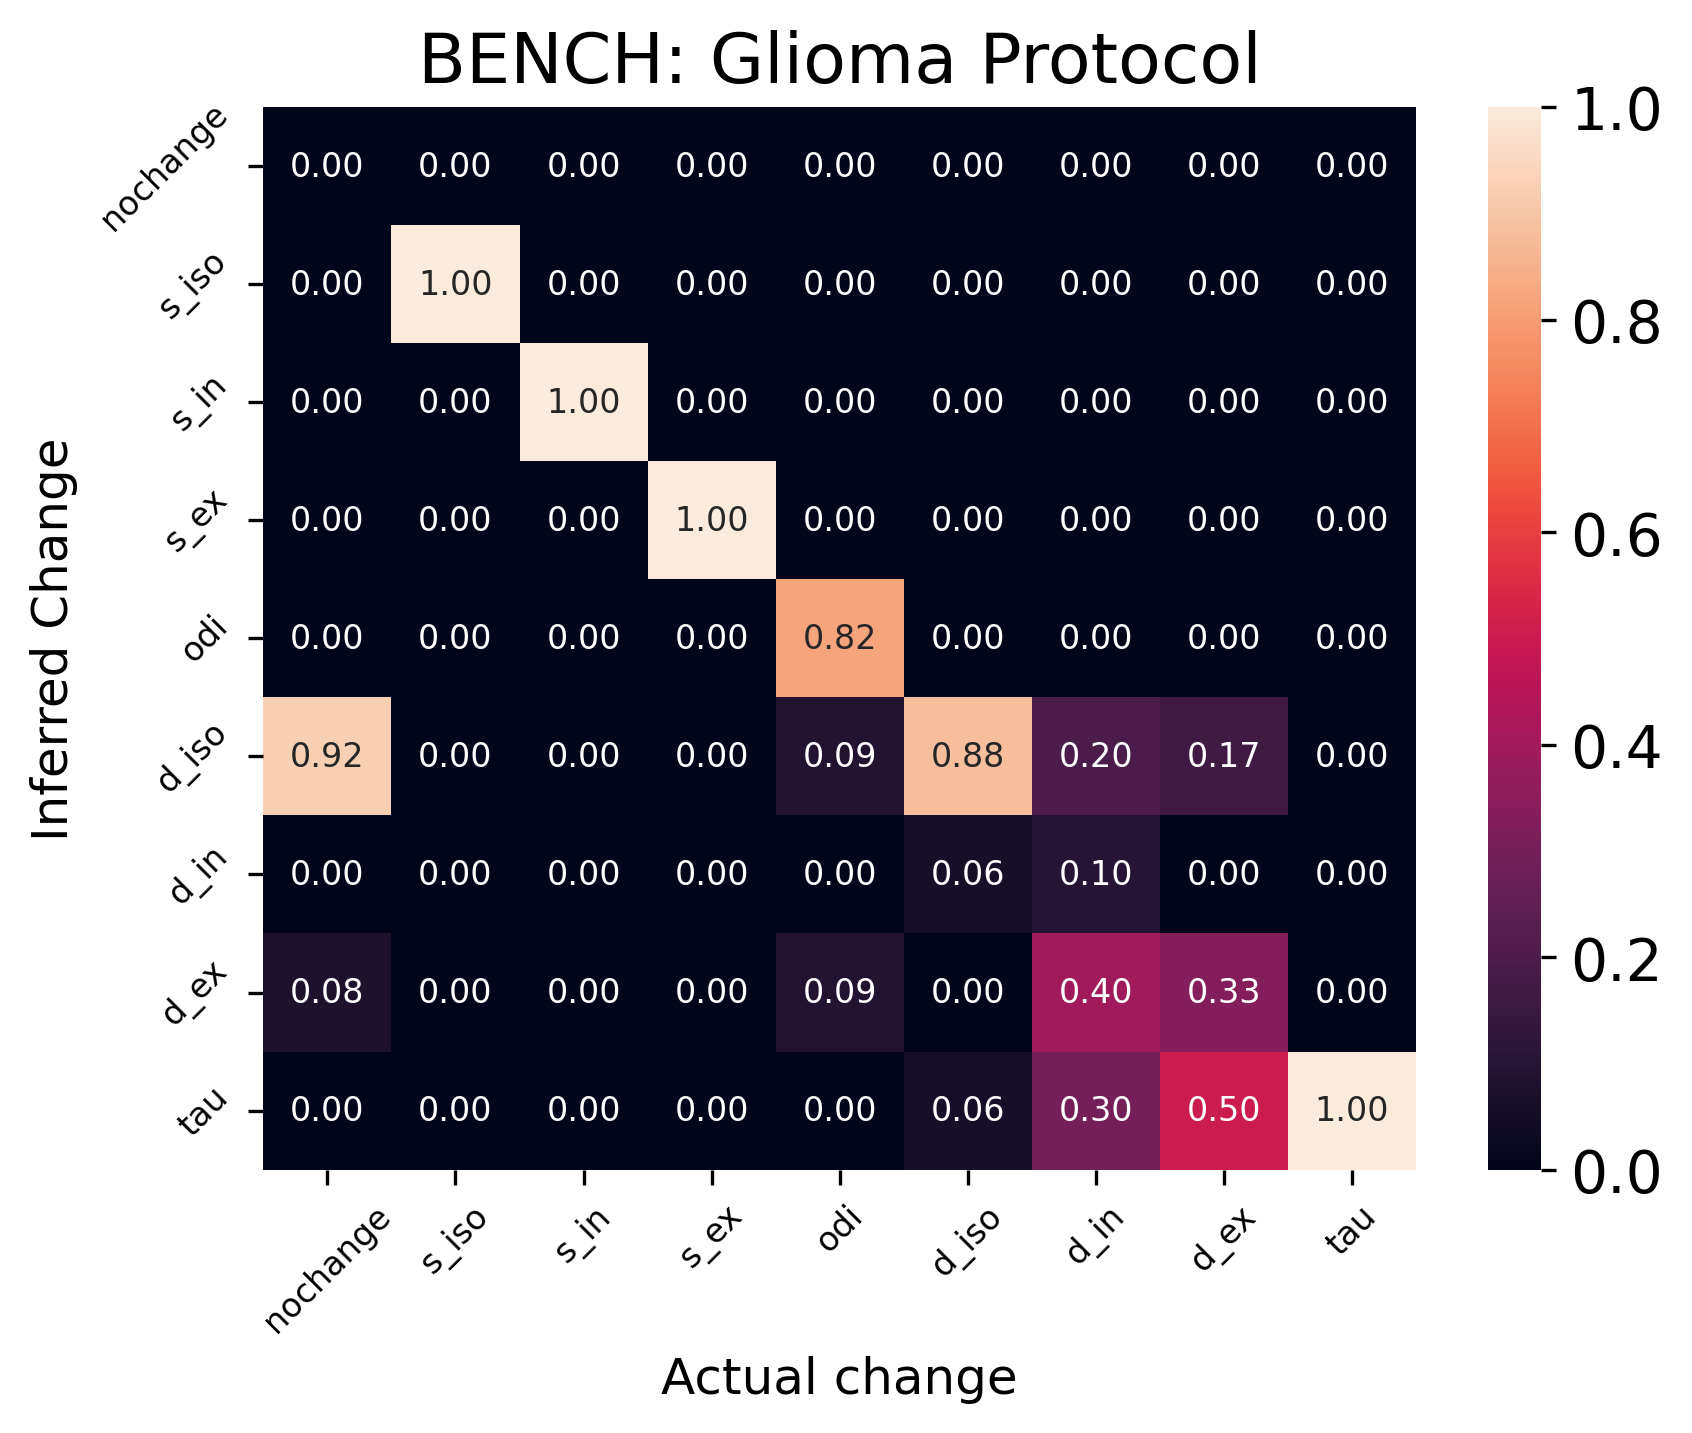

In [14]:
conf_mat = confusion_matrix(true_change, infered_change_bench, normalize='true')
plot.plot_conf_mat(conf_mat, param_names=mdl.model_names, title='BENCH: Glioma Protocol')

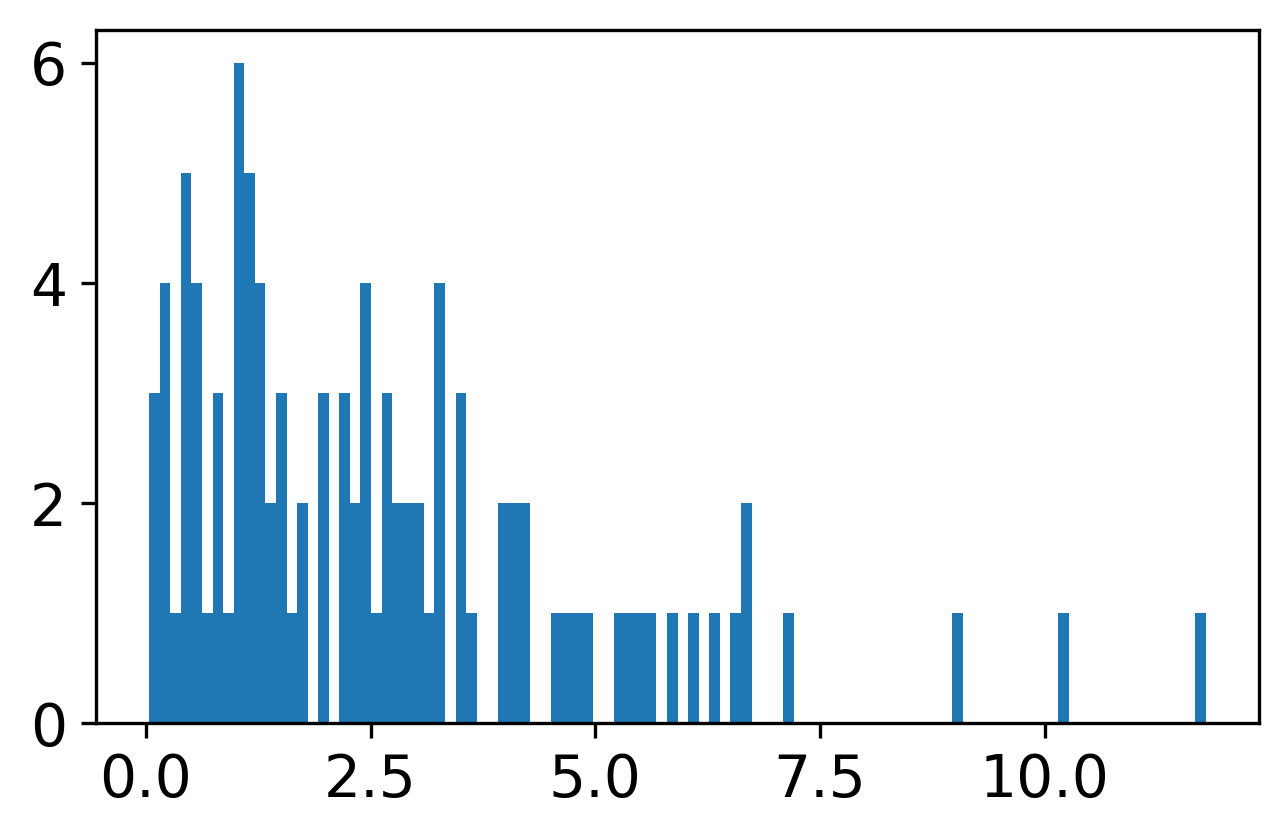

In [11]:
dv, offset, deviation = mdl.estimate_quality_of_fit(data, data2 - data, sn, infered_change_bench, amount)
plt.hist(deviation, 100);

In [12]:
def model_inv_tr(acq, noise_level, **p):
    return forward_model(bval=acq.bvals, bvec=acq.bvecs,**p) + noise_level * np.random.randn(acq.bvecs.shape[0])

def model_inv(**p):
    return forward_model(bval=acq.bvals, bvec=acq.bvecs,**p)

priors_inv = dict()
priors_inv['s_iso'] = st.truncnorm(loc=.5, scale=.2, a=-.5 / .2, b=np.inf)
priors_inv['s_in'] = st.truncnorm(loc=.5, scale=.2, a=-.5 / .2, b=np.inf)
priors_inv['s_ex'] = st.truncnorm(loc=.5, scale=.2, a=-.5 / .2, b=np.inf)
priors_inv.update(priors_bench)
del priors_inv[('s_iso', 's_in', 's_ex')]


tr_inv = change_model.Trainer(forward_model=model_inv_tr, kwargs={'noise_level':0, 'acq':acq}, priors=priors_inv)

true_change_inv, sig1, sig2, sn = tr_inv.generate_test_samples(parallel=False, 
    n_samples=n_test_samples, noise_std=noise_level, n_repeats=2, effect_size=effect_size)
    
def tmp_func(j):
    pe1, std1 = model_inversion.map_fit(sig1[j], np.eye(len(sig1[j])), model_inv, priors_inv)
    pe2, std2 = model_inversion.map_fit(sig2[j], np.eye(len(sig2[j])), model_inv, priors_inv)
        
    return model_inversion.infer_change(np.atleast_2d(pe1), np.atleast_2d(std1), 
                                        np.atleast_2d(pe2), np.atleast_2d(std2), alpha=0.05)

res = Parallel(n_jobs=-1, verbose=True)(delayed(tmp_func)(j) for j in range(n_test_samples))
infered_change_inv = np.squeeze(np.array(res)[:, 0])

Generating 100 test samples:


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
/Users/ecd25/miniconda3/envs/numba-py311/lib/python3.11/site-packages/bench/model_inversion.py:63: RuntimeWarning: invalid value encountered in sqrt
  std = 1 / np.sqrt(np.diag(h))
/Users/ecd25/miniconda3/envs/numba-py311/lib/python3.11/site-packages/bench/model_inversion.py:63: RuntimeWarning: invalid value encountered in sqrt
  std = 1 / np.sqrt(np.diag(h))
/Users/ecd25/miniconda3/envs/numba-py311/lib/python3.11/site-packages/bench/model_inversion.py:63: RuntimeWarning: invalid value encountered in sqrt
  std = 1 / np.sqrt(np.diag(h))
/Users/ecd25/miniconda3/envs/numba-py311/lib/python3.11/site-packages/bench/model_inversion.py:63: RuntimeWarning: invalid value encountered in sqrt
  std = 1 / np.sqrt(np.diag(h))
[Parallel(n_jobs=-1)]: Done  26 tasks      | elapsed:    4.0s
/Users/ecd25/miniconda3/envs/numba-py311/lib/python3.11/site-packages/bench/model_inversion.py:63: RuntimeWarning: invalid value encounte

<Axes: title={'center': 'Parameter estimation: Glioma Protocol'}, xlabel='Actual change', ylabel='Inferred Change'>

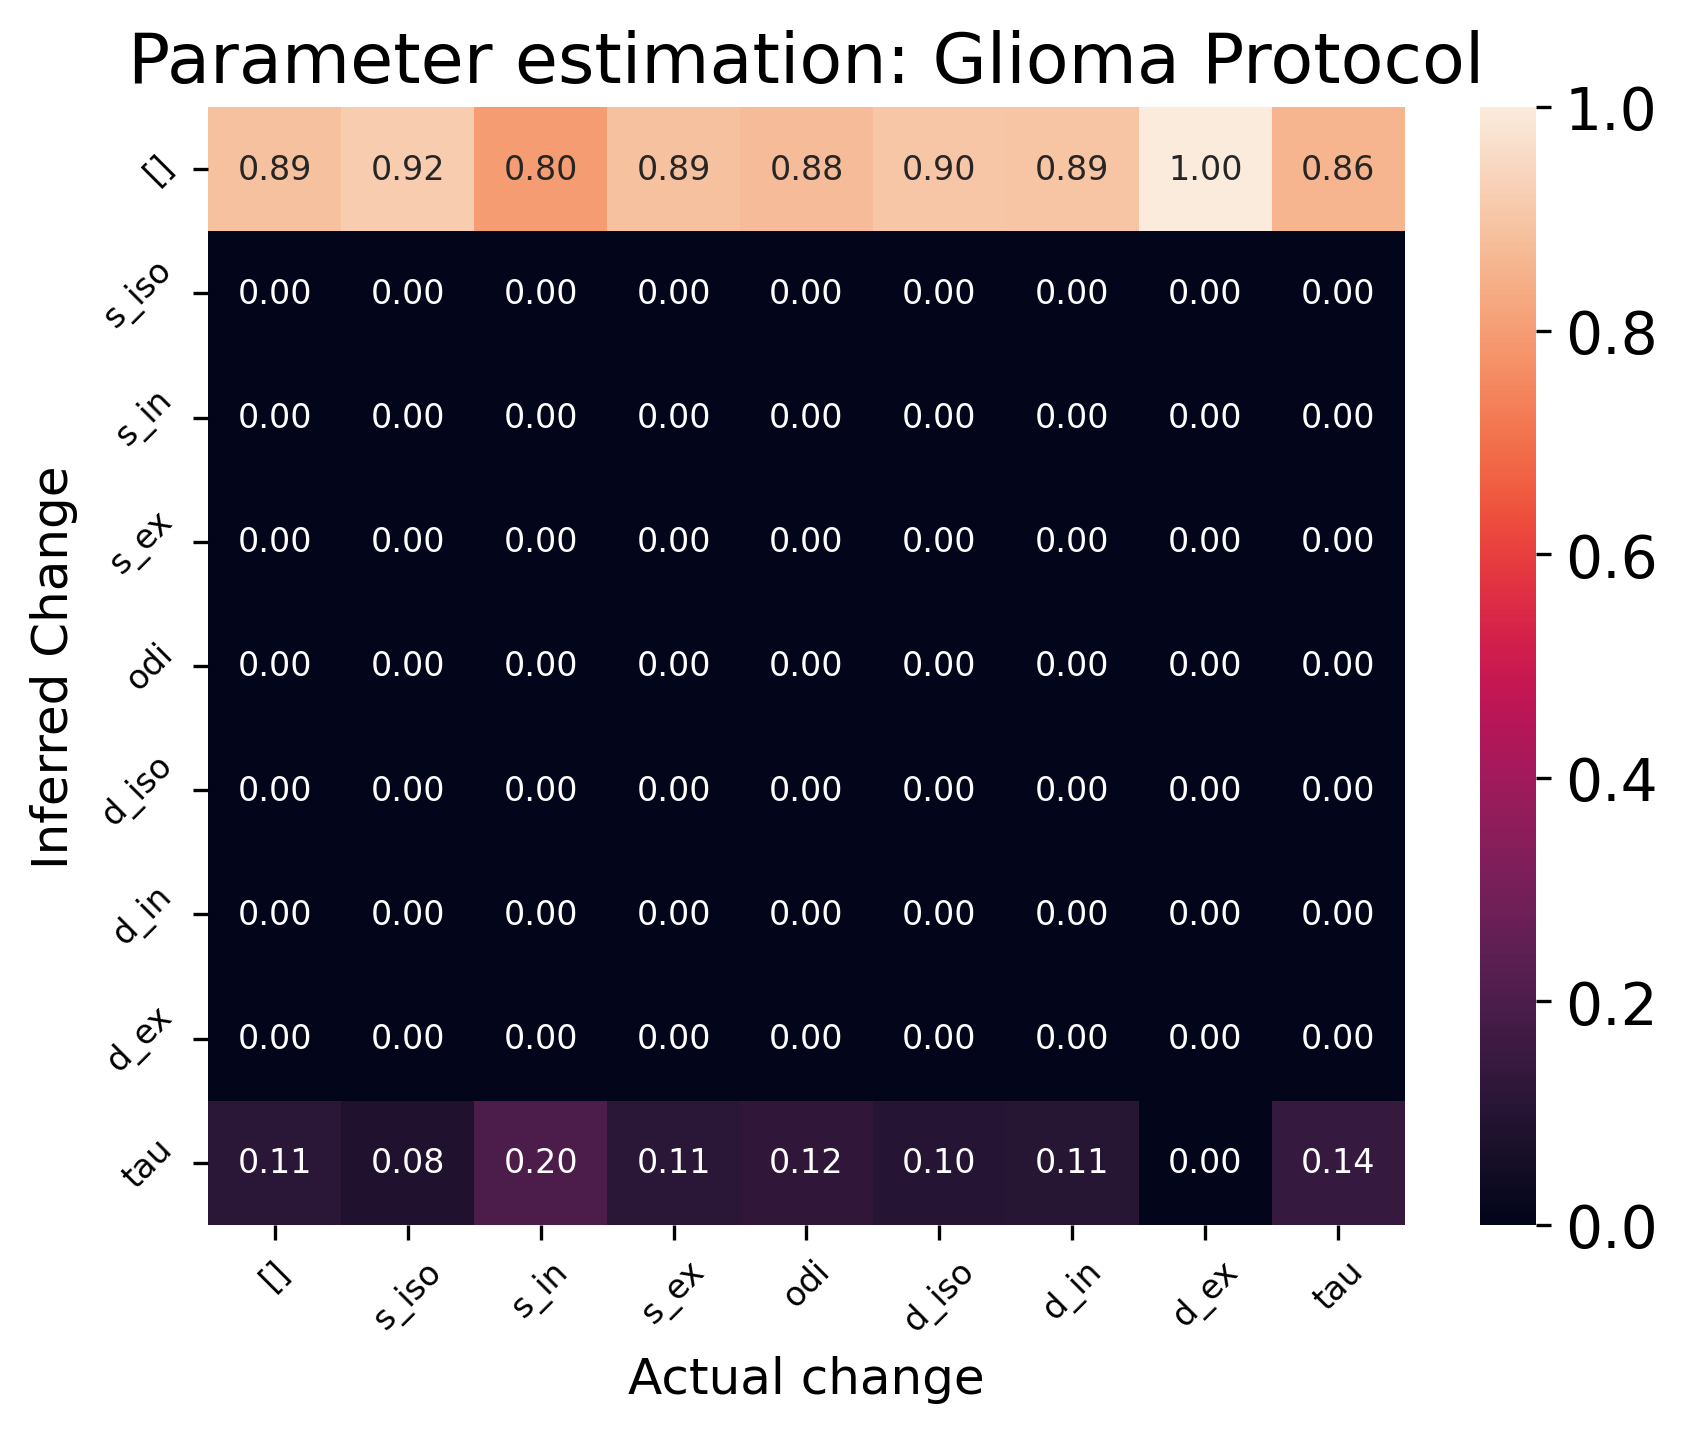

In [15]:
conf_mat_inv = confusion_matrix(true_change_inv, infered_change_inv, normalize='true')
plot.plot_conf_mat(conf_mat_inv, ['[]'] + list(priors_inv.keys()), title='Parameter estimation: Glioma Protocol')